## Imports

In [1]:
import torch # Main PyTorch library
from torch import nn # Neural network module, used for building models
from torch.optim import Adam # Optimizer for training the model
import torchvision.transforms as transforms # For data preprocessing and augmentation
from torch.utils.data import Dataset, DataLoader # For creating custom datasets and loading data in batches
from sklearn.preprocessing import LabelEncoder # For encoding categorical labels into numerical format
import matplotlib.pyplot as plt # For plotting graphs and visualizations
from PIL import Image # Used to read the images from the directory
import numpy as np # For numerical operations
import pandas as pd # For data manipulation and analysis

import os # For interacting with the operating system, such as file paths

device = torch.device("cuda" if torch.cuda.is_available() else "cpu") # Check if GPU is available, otherwise use CPU
print(f"Using device: {device}") # Print the device being used for computation

Using device: cuda


## Reading Data Paths

In [2]:
image_path = []
labels = []

for i in os.listdir("../data/animal-faces/afhq/"):
    for label in os.listdir(f"../data/animal-faces/afhq/{i}"):
        for image in os.listdir(f"../data/animal-faces/afhq/{i}/{label}"):
            labels.append(label)
            image_path.append(f"../data/animal-faces/afhq/{i}/{label}/{image}")

In [3]:
data_df = pd.DataFrame(zip(image_path, labels), columns=["image_paths", "labels"]) # Create a DataFrame with image paths and corresponding labels
data_df.head() # Display the first few rows of the DataFrame

,image_paths,labels
0,../data/animal-faces/afhq/train/cat/flickr_cat...,cat
1,../data/animal-faces/afhq/train/cat/flickr_cat...,cat
2,../data/animal-faces/afhq/train/cat/flickr_cat...,cat
3,../data/animal-faces/afhq/train/cat/flickr_cat...,cat
4,../data/animal-faces/afhq/train/cat/flickr_cat...,cat


## Data Split

- Training: 70%
- Validation: 15%
- Testing: 15%

In [4]:
train = data_df.sample(frac= 0.7, random_state=42) # Randomly sample 70% of the data for training
test = data_df.drop(train.index) # Use the remaining 30% of the data for testing

val = test.sample(frac=0.5, random_state=42) # Randomly sample 50% of the test data for validation
test = test.drop(val.index) # Use the remaining 50% of the test data for testing

> **A note on the split**
>
> At first this felt wrong to me. The dataset already comes with its own `train/` and `val/` folders, but the loop above merges both of them into one `data_df`. So when we do:
>
> ```python
> train = data_df.sample(frac=0.7, random_state=42)
> ```
>
> the new `train` ends up with images from the original `val/` folder too.
>
> After thinking it through, it's actually fine. We're not reusing the original split at all, we're making our own 70/15/15 split from everything. And because `drop(train.index)` removes exactly the rows that went into `train`, every image lands in **exactly one** set. Nothing from training leaks into validation or test.
>
> Respecting the original folders (original `val/` as the test set) would be the cleaner choice if I wanted to compare results with other people. But the goal of this notebook is to get comfortable with PyTorch, so I'm keeping the video's approach.

## Preprocessing Objects

In [5]:
label_encoder = LabelEncoder() # Create an encoder that turns text labels into numbers (it is used later in the code)
label_encoder.fit(data_df["labels"]) # fit() only learns the mapping from labels to numbers, it doesn't convert anything yet

transform = transforms.Compose([
    transforms.Resize((128, 128)), # Resize images to 128x128 pixels
    transforms.ToTensor(), # Convert images to PyTorch tensors
    transforms.ConvertImageDtype(torch.float), # Convert image data type to float
]) # Transform all images to a consistent format for model input (preprocess all images to same properties)

## Custom Dataset Class

In [6]:
class CustomImageDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe
        self.transform = transform
        self.labels = torch.tensor(label_encoder.transform(dataframe['labels'])).to(device)

    def __len__(self):
        return self.dataframe.shape[0]

    def __getitem__(self, idx):
        img_path = self.dataframe.iloc[idx, 0]
        label = self.labels[idx]
        image = Image.open(img_path).convert('RGB')
        if self.transform:
          image = self.transform(image).to(device)

        return image, label

## Create Dataset Objects

In [7]:
train_dataset = CustomImageDataset(dataframe=train, transform=transform) # Create a dataset for training
val_dataset = CustomImageDataset(dataframe=val, transform=transform) # Create a dataset for validation
test_dataset = CustomImageDataset(dataframe=test, transform=transform) # Create a dataset for testing

# see the result of train_dataset
print(train_dataset[0])

(tensor([[[0.6588, 0.6510, 0.6078,  ..., 0.4863, 0.5020, 0.4784],
         [0.5608, 0.6196, 0.6588,  ..., 0.5490, 0.5490, 0.5137],
         [0.5059, 0.5608, 0.6118,  ..., 0.5843, 0.5647, 0.5373],
         ...,
         [0.5529, 0.5608, 0.5686,  ..., 0.3725, 0.3529, 0.3686],
         [0.5569, 0.5569, 0.5647,  ..., 0.3725, 0.3725, 0.3922],
         [0.5176, 0.5098, 0.5137,  ..., 0.4392, 0.4392, 0.4471]],

        [[0.6588, 0.6588, 0.6235,  ..., 0.5255, 0.5882, 0.6000],
         [0.5686, 0.6157, 0.6353,  ..., 0.6000, 0.6431, 0.6392],
         [0.5255, 0.5608, 0.5961,  ..., 0.6588, 0.6745, 0.6745],
         ...,
         [0.5529, 0.5608, 0.5686,  ..., 0.3255, 0.3098, 0.3255],
         [0.5569, 0.5569, 0.5647,  ..., 0.3255, 0.3255, 0.3490],
         [0.5373, 0.5333, 0.5333,  ..., 0.3882, 0.3922, 0.4000]],

        [[0.5412, 0.5020, 0.4118,  ..., 0.2941, 0.3569, 0.3647],
         [0.4431, 0.4824, 0.4902,  ..., 0.3608, 0.3765, 0.3490],
         [0.3373, 0.3843, 0.4275,  ..., 0.3647, 0.3412, 0

## What One Image Looks Like

The first two images of `train_dataset` (`train_dataset[0]` is a dog, `train_dataset[1]` is a cat), followed step by step: original photo → resized to 128 × 128 → split into 3 colour sheets. Each sheet holds 128 × 128 numbers between 0.0 and 1.0, so one image becomes a tensor of shape `(3, 128, 128)`.

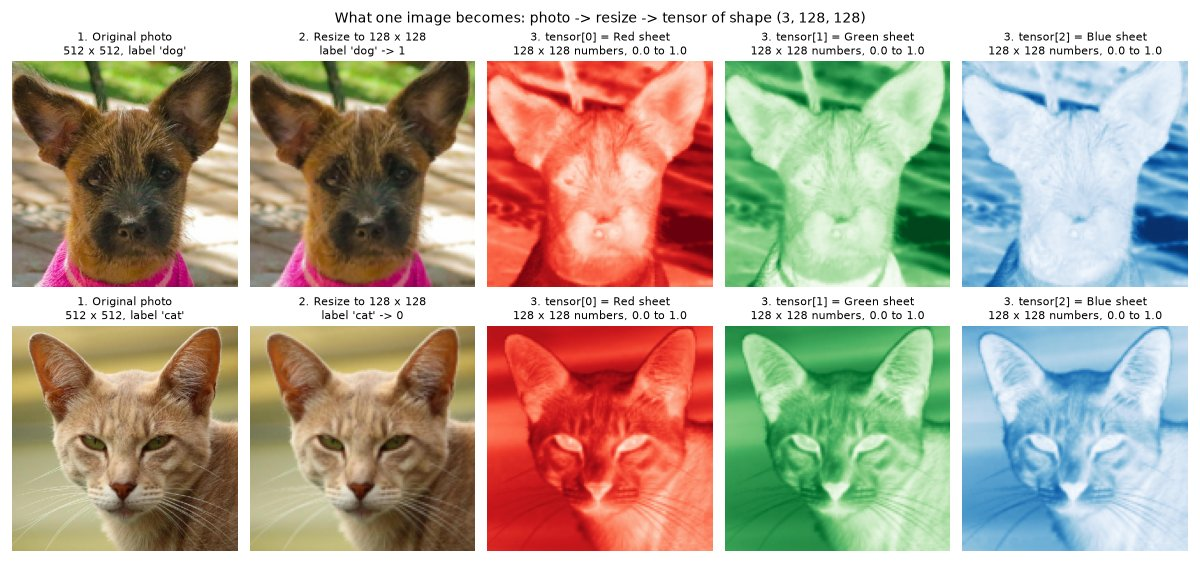

*Figure generated by Claude (AI) from this notebook's data.*

## Visualize Images

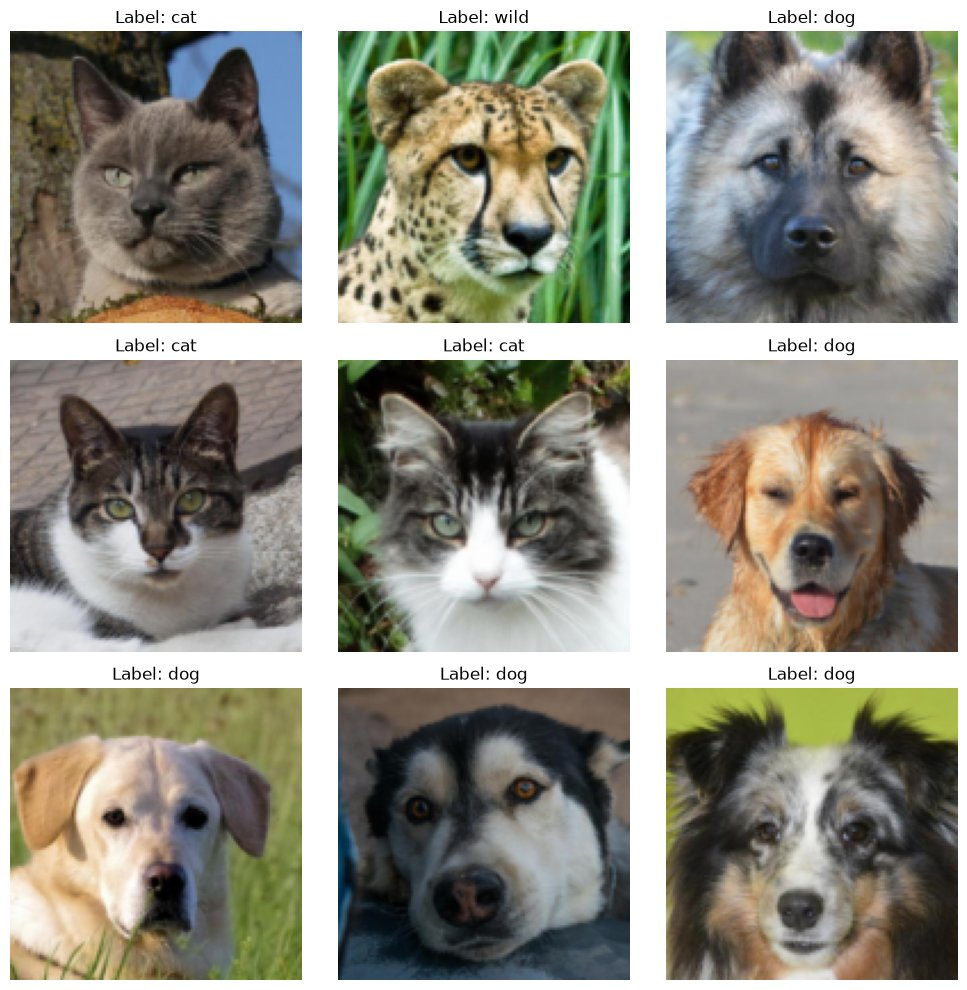

In [8]:
n_rows = 3
n_cols = 3

f, axarr = plt.subplots(n_rows, n_cols, figsize=(10, 10))
for row in range(n_rows):
    for col in range(n_cols):
        idx = np.random.randint(0, len(train_dataset)) # Randomly select an index from the training dataset
        image, label = train_dataset[idx] # Get the image and label corresponding to the randomly selected index
        axarr[row, col].imshow(image.permute(1, 2, 0).cpu().numpy()) # Display the image on the subplot, permuting the dimensions to match the expected format for displaying images (height, width, channels) (permute is used to change the order of dimensions)
        axarr[row, col].set_title(f"Label: {label_encoder.inverse_transform([label.cpu().item()])[0]}") # Set the title of the subplot to the corresponding label, converting the numerical label back to its original string format using the inverse_transform method of the label encoder
        axarr[row, col].axis('off') # Turn off the axis for the subplot to make the visualization cleaner

plt.tight_layout()

## Hyperparameters

In [9]:
LR = 1e-4 # Learning rate for the optimizer (1e-4 means 0.0001, which is a common starting point for learning rates in deep learning)
BATCH_SIZE = 16 # Batch size for training and validation (number of samples processed before the model is updated)
EPOCHS = 10 # Number of epochs for training (one epoch means one complete pass through the entire training dataset)

## Data Loaders

In [10]:
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True) # Create a DataLoader for the training dataset, shuffling the data to ensure randomness
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False) # Create a DataLoader for the validation dataset, not shuffling the data to ensure reproducibility
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False) # Create a DataLoader for the test dataset, not shuffling the data to ensure reproducibility

# what is DataLoader? DataLoader is a PyTorch utility that provides an efficient way to load and iterate over datasets in batches. It takes a dataset as input and allows you to specify the batch size, whether to shuffle the data, and other parameters. It is particularly useful for training deep learning models, as it helps manage memory usage. It can also load data in parallel with multiple workers (`num_workers`), which we don't use here.

## Model

In [11]:
class Net(nn.Module):
    def __init__(self):
      super().__init__()

      self.conv1 = nn.Conv2d(3, 32, kernel_size = 3, padding = 1) # First Convolution layer
      self.conv2 = nn.Conv2d(32, 64, kernel_size = 3, padding = 1) # Second Convolution layer
      self.conv3 = nn.Conv2d(64, 128, kernel_size = 3, padding = 1) # Third Convolution layer
      self.pooling = nn.MaxPool2d(2,2) # The pooling layer, we will be using the same layer after each conv2d.
      self.relu = nn.ReLU() # ReLU Activation function

      self.flatten = nn.Flatten() # Flatten and vectorize the output feature maps that comes from the final convolution layer.
      self.linear = nn.Linear((128 * 16 * 16), 128) # Traditional Dense (Linear)
      self.output = nn.Linear(128, len(data_df['labels'].unique())) # Output Linear Layer


    def forward(self, x):
      x = self.conv1(x) # -> Outputs: (32, 128, 128)
      x = self.pooling(x) # -> Outputs: (32, 64, 64)
      x = self.relu(x)
      x = self.conv2(x) # -> Outputs: (64, 64, 64)
      x = self.pooling(x) # -> Outputs: (64, 32, 32)
      x = self.relu(x)
      x = self.conv3(x) # -> Outputs: (128, 32, 32)
      x = self.pooling(x) # -> Outputs: (128, 16, 16)
      x = self.relu(x)
      x = self.flatten(x)
      x = self.linear(x)
      x = self.output(x)

      return x

model = Net().to(device) # Create an instance of the model and move it to the GPU Device

## Model Summary

This cell is optional. It only shows a summary of the model and the output size of each layer. Keep in mind that `-1` will be replaced by the batch size.

In [12]:
from torchsummary import summary

summary(model, input_size = (3, 128, 128))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 32, 128, 128]             896
         MaxPool2d-2           [-1, 32, 64, 64]               0
              ReLU-3           [-1, 32, 64, 64]               0
            Conv2d-4           [-1, 64, 64, 64]          18,496
         MaxPool2d-5           [-1, 64, 32, 32]               0
              ReLU-6           [-1, 64, 32, 32]               0
            Conv2d-7          [-1, 128, 32, 32]          73,856
         MaxPool2d-8          [-1, 128, 16, 16]               0
              ReLU-9          [-1, 128, 16, 16]               0
          Flatten-10                [-1, 32768]               0
           Linear-11                  [-1, 128]       4,194,432
           Linear-12                    [-1, 3]             387
Total params: 4,288,067
Trainable params: 4,288,067
Non-trainable params: 0
---------------------------

## Loss and Optimizer

In [13]:
# Define loss function and optimizer
criterion = nn.CrossEntropyLoss() # Cross Entropy Loss
optimizer = Adam(model.parameters(), lr=LR) # Adam optimizer

# 🐾 How This Notebook Works, from Zero (study notes)

> 📝 **Note:** This explanation was **written by Claude (AI)** at my request, so I could truly understand what happens from the first cell up to here. All the **code** in this notebook is typed by me while following the video.
>
> All numbers are **real**, calculated from this exact data and this exact code. The model's starting weights are random, so a few numbers (marked *untrained*) will look a bit different every time.

---

## 0. The big picture

```
📁 folders full of photos (afhq/train + afhq/val)
   │  1. collect every file path + its folder name
   ▼
data_df            a table of ADDRESSES, not photos         16,130 rows × 2 columns
   │  2. shuffle and cut 70 / 15 / 15
   ▼
train 11,291   ·   val 2,420   ·   test 2,419
   │  3. prepare two tools: a label dictionary + an image recipe
   ▼
train_dataset  ·  val_dataset  ·  test_dataset             "warehouses" of addresses
   │  4. a photo is opened ONLY when someone asks for it
   ▼
one image  →  tensor (3, 128, 128)          one label  →  0, 1 or 2
   │  5. DataLoader stacks 16 of them
   ▼
one batch  →  images (16, 3, 128, 128)  +  labels (16,)
   │  6. the CNN model
   ▼
3 scores per photo  →  the highest score is the guess (cat / dog / wild)
```

---

## 1. From folders to a table of addresses

The loop `for i in os.listdir(...)` walks through every folder and writes down **where each photo lives** and **which folder it came from**:

| `image_paths` | `labels` |
|---|---|
| `../data/animal-faces/afhq/train/cat/flickr_cat_000002.jpg` | `cat` |
| ... 16,130 rows in total ... | |

- `train/` folder: 14,630 photos. `val/` folder: 1,500 photos. Together: **16,130**.
- ⚠️ **`data_df` holds only text** (addresses and names). **No photo has been opened yet.**

## 2. The split: 70 / 15 / 15

`sample(frac=0.7)` picks 70% of the rows at random, and `drop(...)` keeps the rest. Every photo ends up in **exactly one** group:

| Group | Photos | Role |
|---|---|---|
| `train` | 11,291 | 📘 The practice book: the model **learns** from these |
| `val` | 2,420 | 📝 A practice test after every epoch: **no learning** |
| `test` | 2,419 | 🎓 The final exam, used once at the end: **no learning** |

## 3. Two tools, prepared but not used yet

**Tool 1: the label dictionary**
```python
label_encoder.fit(data_df["labels"])
```
`fit` only **reads** the names and builds a dictionary. Nothing is converted yet.
```
'cat'  → 0
'dog'  → 1
'wild' → 2      (alphabetical order)
```
The model only understands numbers, so the word `"dog"` must become `1`.

**Tool 2: the image recipe**
```python
transform = transforms.Compose([Resize((128, 128)), ToTensor(), ConvertImageDtype(torch.float)])
```
This is just a **written recipe**. No photo has gone through it yet.

## 4. The Dataset: a warehouse of addresses

`CustomImageDataset` is a **warehouse that stores only addresses and label numbers**:

| In `__init__` (runs once) | What is stored |
|---|---|
| `self.dataframe` | the table of addresses (11,291 rows for train) |
| `self.transform` | the recipe from step 3 |
| `self.labels` | the dictionary is **used here**: `['dog', 'cat', 'wild', ...]` → `tensor([1, 0, 2, ...])` |

The photos are **not** loaded here. Turning all 11,291 training photos into tensors at once would need about **2.2 GB**, and my GPU only has 6 GB. So the photo is opened **only when someone asks** for it, inside `__getitem__`:

```
train_dataset[0]
  1. look up the address in row 0  →  .../train/dog/pixabay_dog_001867.jpg
  2. look up its label             →  tensor(1)   (dog)
  3. open the photo                →  512 × 512 pixels, each pixel = 3 numbers (Red, Green, Blue) from 0 to 255
  4. run the recipe                →  resize to 128 × 128 → tensor → divide by 255 → numbers from 0.0 to 1.0
  5. return the pair               →  (image tensor (3, 128, 128),  label tensor(1))
```

**What one image becomes** (see the picture in the *"What One Image Looks Like"* cell above):
- `(3, 128, 128)` = **3 sheets** (Red, Green, Blue), each sheet is 128 × 128 numbers.
- That's 3 × 128 × 128 = **49,152 numbers** for one photo.
- Each number = how bright that colour is at that spot (0.0 = none, 1.0 = full).

## 5. Batches: 16 photos at a time

`DataLoader(train_dataset, batch_size=16, shuffle=True)` asks the warehouse for 16 photos and **stacks** them into one tensor. A real batch:

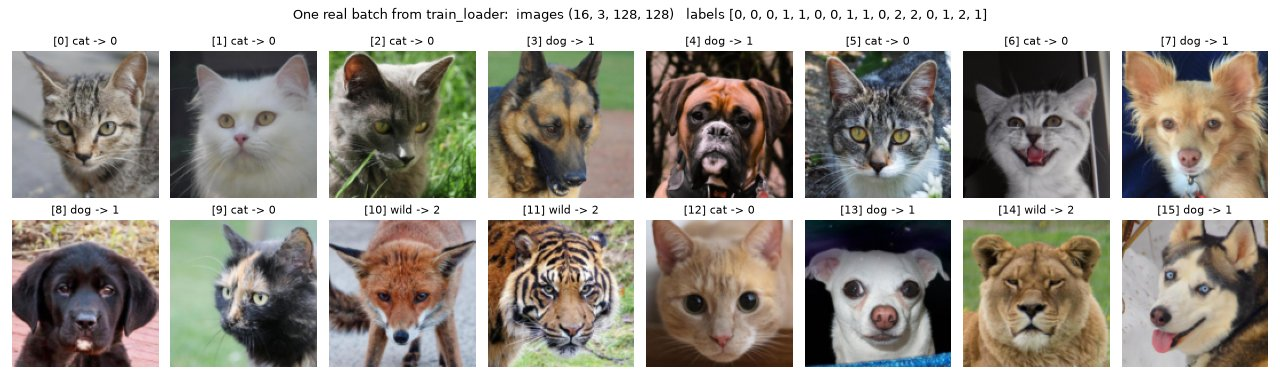

```
images = tensor of shape (16, 3, 128, 128)    →  16 photos × 3 colours × 128 × 128
labels = tensor([0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 2, 2, 0, 1, 2, 1])
```
Stacking only works because **every photo has the same size**. That's why we resize.

| Loader | Batches | Last batch |
|---|---|---|
| `train_loader` | **706** | 11 photos (11,291 = 705 × 16 + 11) |
| `val_loader` | 152 | 4 photos |
| `test_loader` | 152 | 3 photos |

---

## 6. The model: a CNN (Convolutional Neural Network)

### 6.1 The big idea

In Project 01, every input was **10 numbers**. A photo is **49,152 numbers**, and the numbers that matter (an ear, an eye, a nose) can sit **anywhere** in the picture. A CNN handles this in 3 phases:

1. **Look at small patches** to find simple patterns (edges, corners, fur texture).
2. **Shrink the picture** while keeping the strongest signals, so later layers can combine small patterns into bigger ones (ear, eye, snout).
3. **Decide**: turn everything into 3 scores (cat, dog, wild).

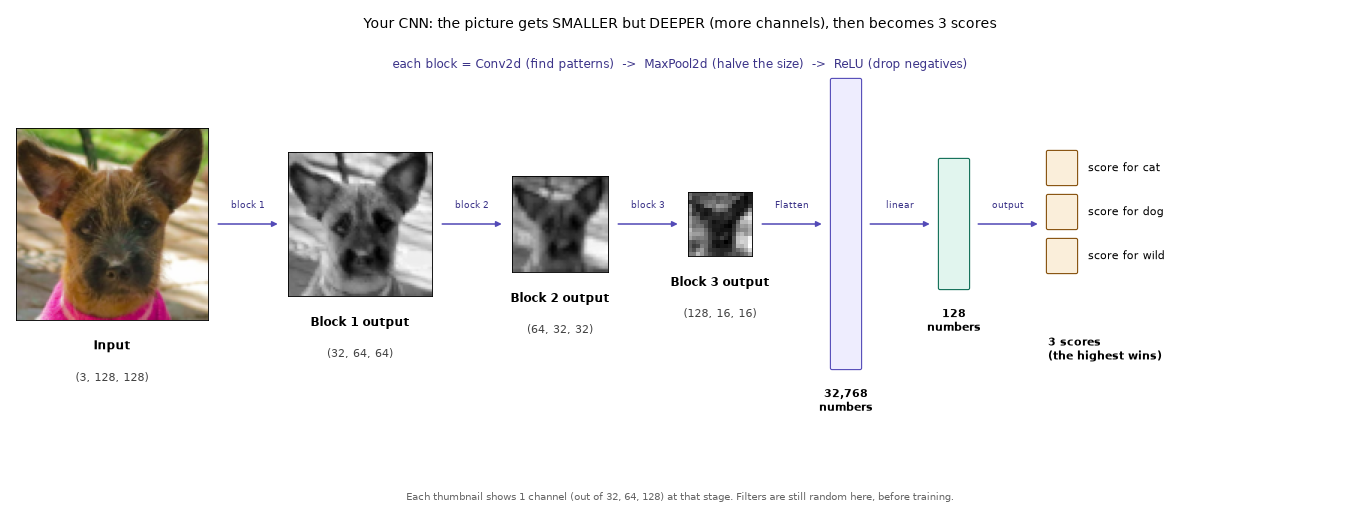

### 6.2 `Conv2d`: the pattern finder 🔍

A **filter** is a tiny 3 × 3 grid of numbers. It **slides** over the picture, one step at a time, and at each spot it does the same "multiply and add" as a neuron in Project 01. If the patch looks like the filter's pattern, the result is **big** (bright). If not, it's **small** (dark).

Two hand-made filters on the dog photo, to show the idea:

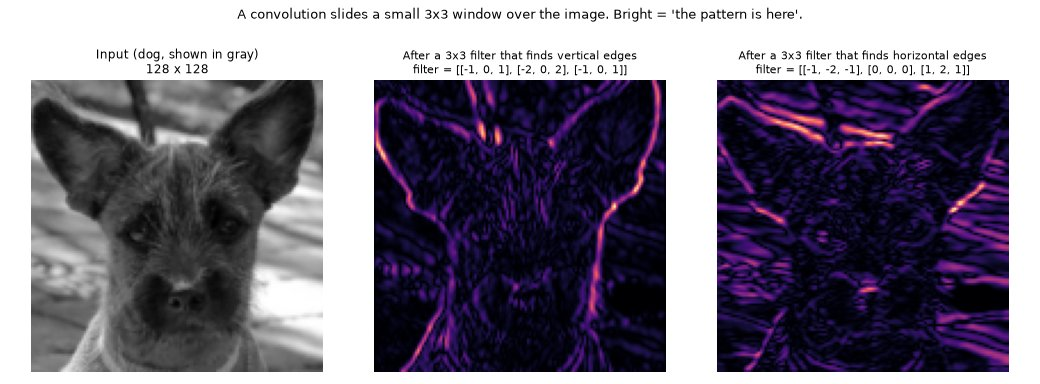

- The **vertical edges** filter lights up the sides of the ears and face.
- The **horizontal edges** filter lights up the stripes in the background.
- My model **does not use hand-made filters**. It starts with **random** filters and **learns** the best ones during training.

`nn.Conv2d(3, 32, kernel_size=3, padding=1)` means:
- `3`: it reads 3 sheets (Red, Green, Blue).
- `32`: it has **32 different filters**, so it produces **32 new sheets** (each one = "where is *my* pattern?").
- `kernel_size=3`: each filter is 3 × 3.
- `padding=1`: adds a 1-pixel frame around the picture so the size stays 128 × 128.

### 6.3 `MaxPool2d(2, 2)`: shrink, keep the strongest 🗜️

Cut each sheet into 2 × 2 squares and keep **only the biggest number** in each square. The size is **halved**. (Toy example:)
```
[1 3 | 2 0]
[5 2 | 1 4]      →     [5 4]
-----------            [1 8]
[0 1 | 7 2]
[1 0 | 3 8]
```
"Was the pattern found **somewhere** in this area?" → keep that answer, throw away the exact spot.

### 6.4 `ReLU`: drop the negatives ✂️

```
[-0.7, 0.3, -0.1, 1.2]   →   [0, 0.3, 0, 1.2]
```
Any negative number becomes 0. This is the **"bender"** that Project 01's model didn't have. It lets the model learn **curved** decision lines instead of only straight ones. Right after the first conv (before training), about **half** of all the numbers are negative, so ReLU really changes things.

### 6.5 `Flatten`, then the two `Linear` layers

- `Flatten`: the final (128, 16, 16) block becomes **one long row of 32,768 numbers**.
- `self.linear`: 32,768 → **128** numbers (the same `nn.Linear` as Project 01, just much bigger).
- `self.output`: 128 → **3** numbers: one score for cat, dog and wild.

### 6.6 One real batch through the model (shapes)

| Step | Shape | In plain words |
|---|---|---|
| input | `(16, 3, 128, 128)` | 16 photos, 3 colour sheets each |
| `conv1` | `(16, 32, 128, 128)` | 32 pattern sheets per photo |
| `pooling` + `relu` | `(16, 32, 64, 64)` | half the size |
| `conv2` | `(16, 64, 64, 64)` | 64 pattern sheets |
| `pooling` + `relu` | `(16, 64, 32, 32)` | half again |
| `conv3` | `(16, 128, 32, 32)` | 128 pattern sheets |
| `pooling` + `relu` | `(16, 128, 16, 16)` | half again |
| `flatten` | `(16, 32768)` | one long row per photo |
| `linear` | `(16, 128)` | 128 summary numbers per photo |
| `output` | `(16, 3)` | **3 scores per photo** |

**The picture gets smaller (128 → 64 → 32 → 16) but deeper (3 → 32 → 64 → 128 sheets).**

### 6.7 Reading the `summary` (where the 4,288,067 parameters live)

| Layer | How the parameters are counted | Params |
|---|---|---|
| `conv1` | 32 filters × (3 × 3 × 3 weights + 1 bias) | 896 |
| `conv2` | 64 filters × (3 × 3 × 32 + 1) | 18,496 |
| `conv3` | 128 filters × (3 × 3 × 64 + 1) | 73,856 |
| `linear` | 32,768 × 128 weights + 128 biases | **4,194,432** |
| `output` | 128 × 3 + 3 | 387 |
| Pooling, ReLU, Flatten | fixed rules, nothing to learn | 0 |
| **Total** | | **4,288,067** |

😮 **97.8%** of all parameters sit in one layer: `linear`. The conv filters are tiny because the **same small filter is reused at every spot** of the picture.

`-1` in the summary means "however many photos are in the batch" (16 here).

---

## 7. From 3 scores to an answer

The model gives **3 raw scores** (called *logits*). For the first photo of the batch above (a **cat**), before training:
```
scores (logits)  = [ 0.0617, -0.0629,  0.0665]      ← cat, dog, wild
softmax (%)      = [ 34.6%,   30.6%,   34.8%]       ← turned into percentages that add up to 100%
guess (highest)  = wild   ❌  (the true answer is cat)
```
The untrained model is basically guessing **1 out of 3**: it got **5 of the 16** photos right.

### Loss: `nn.CrossEntropyLoss()`
- It turns the 3 scores into percentages (softmax) **by itself**, so the model does **not** need a softmax or sigmoid layer at the end.
- Penalty = **−log(% given to the correct answer)**. For the cat above: −log(0.346) = **1.06**.
- The batch loss is **1.106**, almost exactly log(3) = 1.099, the "pure guessing between 3 classes" level. Training should push it down.
- The labels stay simple numbers (0, 1, 2). No extra work needed.

### Optimizer: `Adam(model.parameters(), lr=1e-4)`
- It holds all **4,288,067 knobs**.
- `lr = 0.0001`: a step **10× smaller** than Project 01. A smaller step is a common, safer choice for a much bigger model.

---

## 8. What training will look like (next section)

Exactly the same 4 steps as Project 01, for **every batch**:
```
① GUESS           model(images)                → (16, 3) scores
② MEASURE         criterion(scores, labels)    → 1 loss number
③ FIND DIRECTION  loss.backward()              → a grad for all 4.29 million knobs
④ FIX             optimizer.step()             → nudge every knob a tiny bit
   optimizer.zero_grad()                       → clear the notes for the next batch
```
- 1 epoch = **706 batches** = 706 small fixes. 10 epochs = **7,060** fixes.
- To count correct answers, the guess is the **position of the highest score** (`argmax`): position 0 = cat, 1 = dog, 2 = wild.

---

## 9. Project 01 vs Project 02

| | Project 01 (rice) | Project 02 (animal faces) |
|---|---|---|
| One input | 10 numbers | (3, 128, 128) = 49,152 numbers |
| Dataset loads data | all at once in `__init__` | one photo at a time in `__getitem__` |
| Labels | 0 / 1 (2 classes) | 0 / 1 / 2 (3 classes) |
| Model | 2 `Linear` layers | 3 conv blocks + 2 `Linear` layers |
| "Bender" (activation) | none | `ReLU` |
| Output | 1 number → `Sigmoid` → 0..1 | 3 scores → highest wins |
| Loss | `BCELoss` | `CrossEntropyLoss` |
| Parameters | 121 | 4,288,067 |
| Learning rate | 0.001 | 0.0001 |

---

## 10. Mini dictionary

| Term | Simple meaning |
|---|---|
| **Channel** | One "sheet" of numbers. A photo starts with 3 (R, G, B). After `conv1` there are 32 |
| **Filter / kernel** | A tiny 3 × 3 grid that looks for one pattern |
| **Convolution** | Sliding a filter over the picture and doing multiply-and-add at every spot |
| **Feature map** | The new sheet a filter produces: "where is my pattern?" |
| **Padding** | A 1-pixel frame added around the picture so its size doesn't shrink |
| **Max pooling** | Keep only the biggest number in each 2 × 2 square: halves the size |
| **ReLU** | Turn negatives into 0: lets the model learn curved shapes |
| **Flatten** | Turn a block of numbers into one long row |
| **Logits** | The raw scores before turning them into percentages |
| **Softmax** | Turns scores into percentages that add up to 100% |
| **argmax** | "Which position has the highest number?" → the guess |

---

## ✨ Worth knowing (feel free to skip)

- Between `self.linear` and `self.output` there is **no ReLU** (the same as in the video). That works, but those two layers then behave like a single `Linear` layer. Adding a ReLU there is a common small improvement.
- The comments in my `forward` (like `# -> Outputs: (32, 128, 128)`) leave out the batch size. The real shape is `(16, 32, 128, 128)`, with 16 photos in front.

## Training

In [14]:
total_loss_train_plot = []
total_loss_validation_plot = []
total_acc_train_plot = []
total_acc_validation_plot = []


for epoch in range(EPOCHS):
  total_acc_train = 0
  total_loss_train = 0
  total_loss_val = 0
  total_acc_val = 0

  for inputs, labels in train_loader:
    optimizer.zero_grad()
    outputs = model(inputs)
    train_loss = criterion(outputs, labels)
    total_loss_train += train_loss.item()
    train_loss.backward()

    train_acc = (torch.argmax(outputs, axis = 1) == labels).sum().item()
    total_acc_train += train_acc
    optimizer.step()

  with torch.no_grad():
    for inputs, labels in val_loader:
      outputs = model(inputs)
      val_loss = criterion(outputs, labels)
      total_loss_val += val_loss.item()

      val_acc = (torch.argmax(outputs, axis = 1) == labels).sum().item()
      total_acc_val += val_acc

  total_loss_train_plot.append(round(total_loss_train/len(train_loader), 4))
  total_loss_validation_plot.append(round(total_loss_val/len(val_loader), 4))
  total_acc_train_plot.append(round(total_acc_train/(train_dataset.__len__())*100, 4))
  total_acc_validation_plot.append(round(total_acc_val/(val_dataset.__len__())*100, 4))
  print(f'''Epoch {epoch+1}/{EPOCHS}, Train Loss: {round(total_loss_train/len(train_loader), 4)} Train Accuracy {round((total_acc_train)/train_dataset.__len__() * 100, 4)}
              Validation Loss: {round(total_loss_val/len(val_loader), 4)} Validation Accuracy: {round((total_acc_val)/val_dataset.__len__() * 100, 4)}''')
  print("="*25)

Epoch 1/10, Train Loss: 0.4843 Train Accuracy 80.2852
              Validation Loss: 0.2644 Validation Accuracy: 90.1653


Epoch 2/10, Train Loss: 0.2193 Train Accuracy 92.1265
              Validation Loss: 0.1632 Validation Accuracy: 93.8843


Epoch 3/10, Train Loss: 0.1386 Train Accuracy 95.2529
              Validation Loss: 0.1395 Validation Accuracy: 94.9587


Epoch 4/10, Train Loss: 0.0995 Train Accuracy 96.5105
              Validation Loss: 0.12 Validation Accuracy: 95.9504


Epoch 5/10, Train Loss: 0.077 Train Accuracy 97.0507
              Validation Loss: 0.1122 Validation Accuracy: 95.6198


Epoch 6/10, Train Loss: 0.0611 Train Accuracy 97.8301
              Validation Loss: 0.1882 Validation Accuracy: 93.6364


Epoch 7/10, Train Loss: 0.0451 Train Accuracy 98.4412
              Validation Loss: 0.108 Validation Accuracy: 96.5702


Epoch 8/10, Train Loss: 0.0321 Train Accuracy 98.9106
              Validation Loss: 0.1564 Validation Accuracy: 94.6694


Epoch 9/10, Train Loss: 0.0264 Train Accuracy 99.0789
              Validation Loss: 0.1173 Validation Accuracy: 96.1157


Epoch 10/10, Train Loss: 0.0231 Train Accuracy 99.2295
              Validation Loss: 0.1266 Validation Accuracy: 96.5702


## Testing

In [15]:
with torch.no_grad(): # torch.no_grad() is a context manager that disables gradient calculation, which reduces memory consumption and speeds up computations during inference (evaluation) since gradients are not needed when making predictions.
  total_loss_test = 0
  total_acc_test = 0
  for inputs, labels in test_loader:
    predictions = model(inputs)

    acc = (torch.argmax(predictions, axis = 1) == labels).sum().item()
    total_acc_test += acc
    test_loss = criterion(predictions, labels)
    total_loss_test += test_loss.item()

print(f"Accuracy Score is: {round((total_acc_test/test_dataset.__len__()) * 100, 4)} and Loss is {round(total_loss_test/len(test_loader), 4)}")

Accuracy Score is: 96.6515 and Loss is 0.1303


## Plotting Training Progress

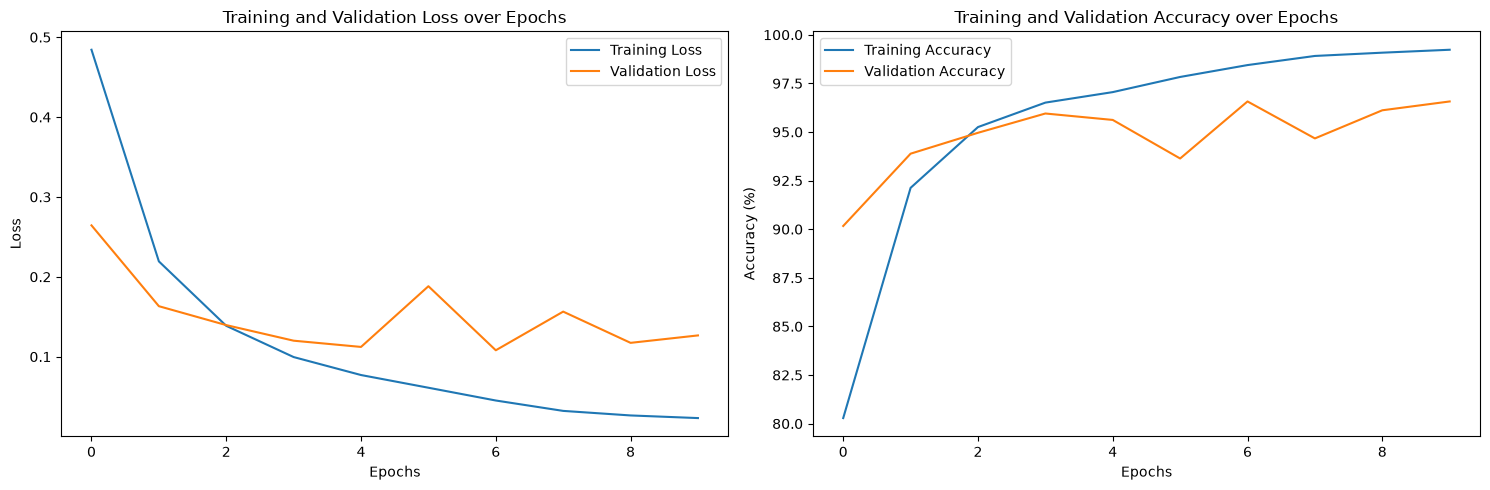

In [16]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5))

axs[0].plot(total_loss_train_plot, label = "Training Loss")
axs[0].plot(total_loss_validation_plot, label = "Validation Loss")
axs[0].set_title("Training and Validation Loss over Epochs")
axs[0].set_xlabel("Epochs")
axs[0].set_ylabel("Loss")
axs[0].legend()

axs[1].plot(total_acc_train_plot, label = "Training Accuracy")
axs[1].plot(total_acc_validation_plot, label = "Validation Accuracy")
axs[1].set_title("Training and Validation Accuracy over Epochs")
axs[1].set_xlabel("Epochs")
axs[1].set_ylabel("Accuracy (%)")
axs[1].legend()

plt.tight_layout() # Adjusts the spacing between subplots to prevent overlap and ensure a clean layout
plt.show() # Display the plots for loss and accuracy over epochs

## Inference

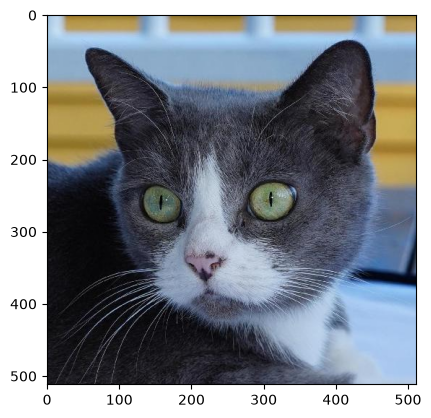


Prediction: 



array(['cat'], dtype=object)

In [17]:
# 1. Read image
# 2. Transform using transform object
# 3. Predict with the model
# 4. Get the predicted label and convert it back to string using inverse_transform of label_encoder

def predict_image(image_path):
  image = Image.open(image_path).convert('RGB')
  image = transform(image).to(device)

  output = model(image.unsqueeze(0))
  output = torch.argmax(output, axis = 1).item()
  return label_encoder.inverse_transform([output])

## Visualize the image
image_to_predict = "../data/animal-faces/afhq/train/cat/flickr_cat_000006.jpg" # A cat photo from our test split, so the model never saw it during training
image = Image.open(image_to_predict)
plt.imshow(image)
plt.show()


## Predict
print()
print("Prediction: \n")
predict_image(image_to_predict)

## Predictions on Unseen Test Photos

12 random photos from the **test set** (the model never saw them during training). A **green** title means the guess is correct, a **red** title means it's wrong.

*These two extra visualization cells were added with help from Claude (AI).*

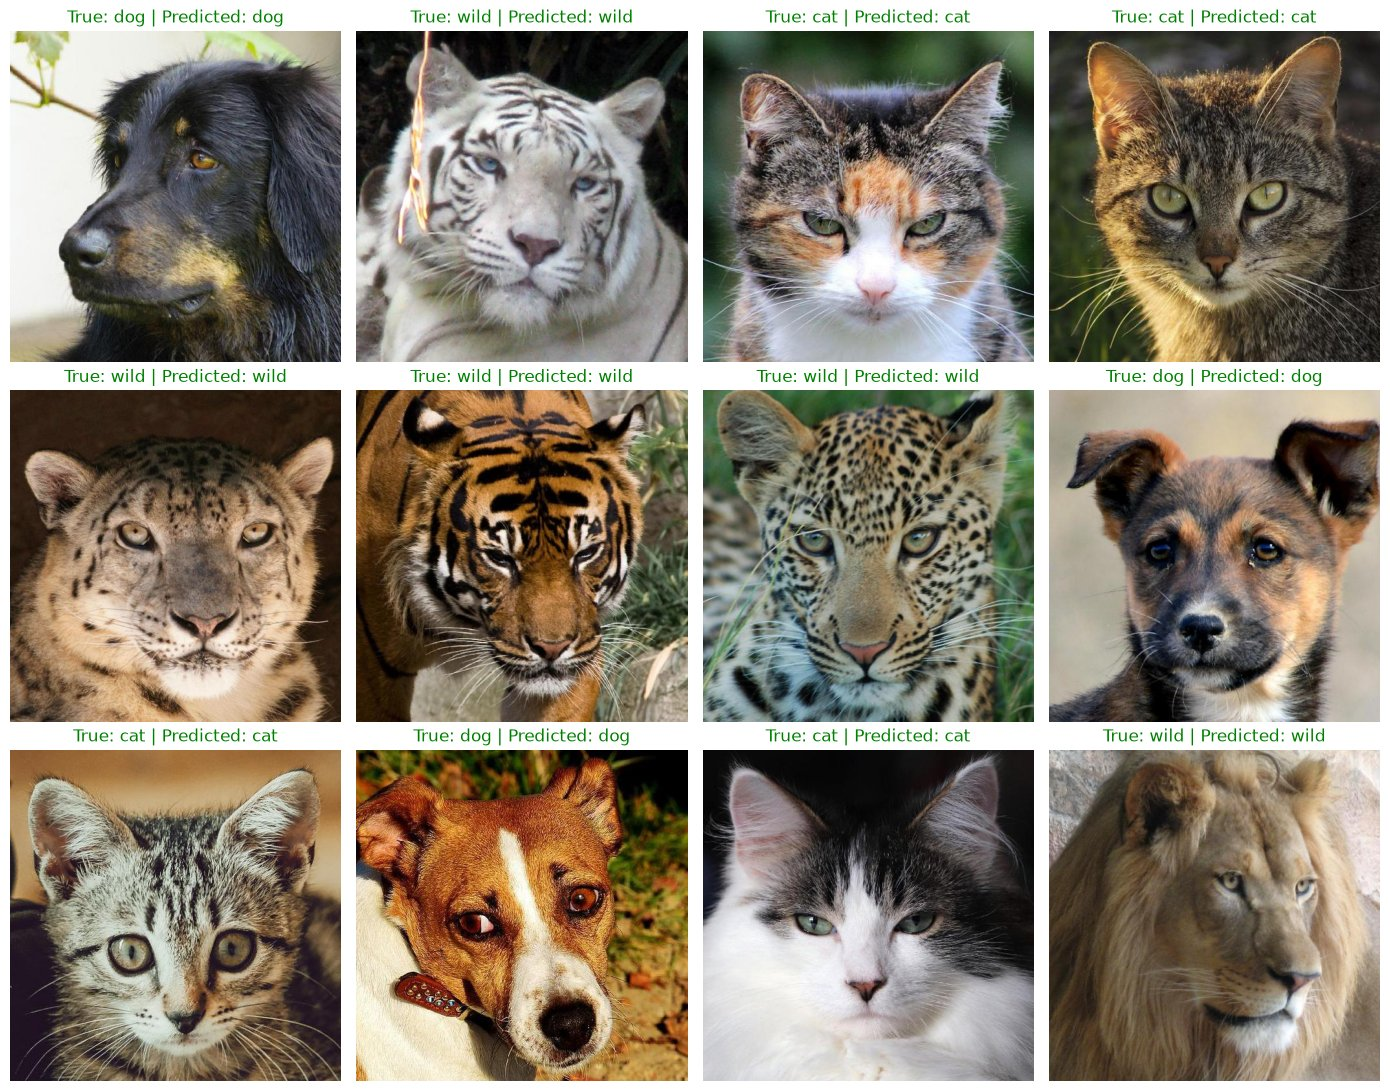

In [18]:
n_rows = 3
n_cols = 4
sample = test.sample(n_rows * n_cols, random_state=7) # 12 random rows from the test table

f, axarr = plt.subplots(n_rows, n_cols, figsize=(14, 11))
with torch.no_grad():
  for ax, (path, true_label) in zip(axarr.flat, sample.itertuples(index=False)):
    predicted_label = predict_image(path)[0] # Same function as in the Inference cell
    ax.imshow(Image.open(path).convert('RGB'))
    ax.set_title(f"True: {true_label} | Predicted: {predicted_label}", color="green" if predicted_label == true_label else "red")
    ax.axis('off')

plt.tight_layout()
plt.show()

### Where the Model Gets It Wrong

Go through the whole test set, collect every wrong guess, and show some of them. Looking at mistakes is often more useful than looking at the accuracy number.

Wrong guesses: 81 out of 2419 test photos


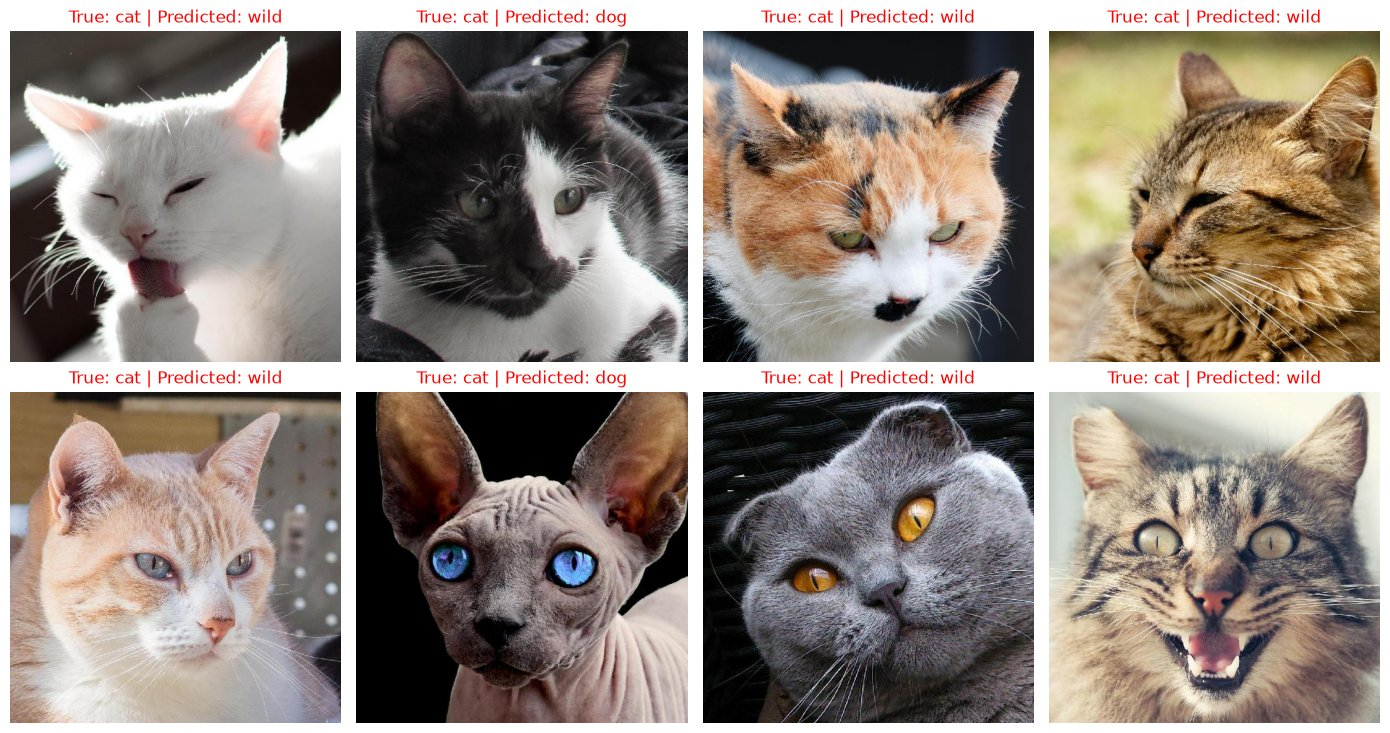

In [19]:
wrong = [] # (image path, true label, predicted label)
position = 0 # test_loader is not shuffled, so batches follow the order of the test table

with torch.no_grad():
  for inputs, labels in test_loader:
    predicted = torch.argmax(model(inputs), axis = 1)
    for i in range(len(labels)):
      if predicted[i] != labels[i]:
        wrong.append((test.iloc[position + i, 0], labels[i].item(), predicted[i].item()))
    position += len(labels)

print(f"Wrong guesses: {len(wrong)} out of {len(test_dataset)} test photos")

f, axarr = plt.subplots(2, 4, figsize=(14, 7.5))
for ax, (path, true_label, predicted_label) in zip(axarr.flat, wrong[:8]):
  true_name = label_encoder.inverse_transform([true_label])[0]
  predicted_name = label_encoder.inverse_transform([predicted_label])[0]
  ax.imshow(Image.open(path).convert('RGB'))
  ax.set_title(f"True: {true_name} | Predicted: {predicted_name}", color="red")
  ax.axis('off')

plt.tight_layout()
plt.show()